<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/sam2_exploracion_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ✂️ Explorando SAM 2 (Segment Anything 2) paso a paso
Segmentación promptable en **imágenes y video**: puntos, cajas, refinamiento con máscaras, generación automática, propagación en video, multi-objeto y comparación de tamaños.
Repositorio: https://github.com/facebookresearch/sam2
> **Activa GPU:** Entorno de ejecución → Cambiar tipo de entorno → T4 GPU. La instalación y la descarga del checkpoint tardan unos minutos.

## 0. Instalación y checkpoints (SAM 2.1)

In [ ]:
!git clone -q https://github.com/facebookresearch/sam2.git
%cd sam2
!pip -q install -e .
!mkdir -p checkpoints
BASE = "https://dl.fbaipublicfiles.com/segment_anything_2/092824"
!wget -q -nc -P checkpoints {BASE}/sam2.1_hiera_large.pt
!wget -q -nc -P checkpoints {BASE}/sam2.1_hiera_tiny.pt
!ls -lh checkpoints

/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
total 1006M
-rwxr-xr-x 1 root root 2.6K Nov  3 17:24 download_ckpts.sh
-rw-r--r-- 1 root root 857M Sep 29  2024 sam2.1_hiera_large.pt
-rw-r--r-- 1 root root 149M Sep 29  2024 sam2.1_hiera_tiny.pt


In [ ]:
import os, glob, time, cv2, torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sam2.build_sam import build_sam2, build_sam2_video_predictor
from sam2.sam2_image_predictor import SAM2ImagePredictor
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    torch.autocast("cuda", dtype=torch.bfloat16).__enter__()
    if torch.cuda.get_device_properties(0).major >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True

MODELS = {"tiny":  ("checkpoints/sam2.1_hiera_tiny.pt",  "configs/sam2.1/sam2.1_hiera_t.yaml"),
          "large": ("checkpoints/sam2.1_hiera_large.pt", "configs/sam2.1/sam2.1_hiera_l.yaml")}
SIZE = "large"
CKPT, CFG = MODELS[SIZE]

# ---------- utilidades de visualización ----------
def show_mask(mask, ax, color=None, border=True):
    color = np.array([30/255, 144/255, 255/255, 0.6]) if color is None else color
    h, w = mask.shape[-2:]; m = mask.reshape(h, w).astype(np.uint8)
    ax.imshow(m[..., None] * color.reshape(1, 1, -1))
    if border:
        for c in cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]:
            ax.plot(c[:, 0, 0], c[:, 0, 1], color="white", linewidth=1.5)

def show_points(coords, labels, ax, size=250):
    pos, neg = coords[labels == 1], coords[labels == 0]
    ax.scatter(pos[:, 0], pos[:, 1], color="lime", marker="*", s=size, edgecolor="white", linewidth=1.2)
    ax.scatter(neg[:, 0], neg[:, 1], color="red", marker="*", s=size, edgecolor="white", linewidth=1.2)

def show_box(box, ax):
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, edgecolor="lime", facecolor=(0, 0, 0, 0), lw=2))

def panel(image, masks, scores=None, points=None, labels=None, box=None, titles=None, size=6):
    fig, ax = plt.subplots(1, len(masks), figsize=(size*len(masks), size*0.75))
    ax = np.atleast_1d(ax)
    for i, m in enumerate(masks):
        ax[i].imshow(image); show_mask(m, ax[i])
        if points is not None: show_points(points, labels, ax[i])
        if box is not None: show_box(box, ax[i])
        ax[i].set_title(titles[i] if titles else (f"Máscara {i+1} · score {scores[i]:.3f}" if scores is not None else ""), fontsize=12)
        ax[i].axis("off")
    plt.tight_layout(); plt.show()

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

device: cuda


## 1. Cargar el modelo e imágenes de ejemplo

Parámetros: 224.4 M


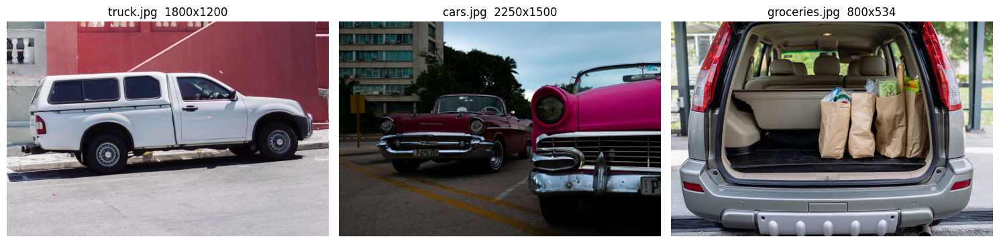

In [ ]:
sam2 = build_sam2(CFG, CKPT, device=device)
predictor = SAM2ImagePredictor(sam2)
print("Parámetros:", round(sum(p.numel() for p in sam2.parameters())/1e6, 1), "M")

IMG = {n: np.array(Image.open(f"notebooks/images/{n}.jpg").convert("RGB")) for
       n in ["truck", "cars", "groceries"]}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (n, im) in zip(ax,
                      IMG.items()): a.imshow(im); a.set_title(f"{n}.jpg
                      {im.shape[1]}x{im.shape[0]}"); a.axis("off")
plt.tight_layout(); plt.show()

## 2. Prompt de un punto → 3 máscaras candidatas (`multimask_output=True`)

masks: (3, 1200, 1800) | scores: [0.773 0.652 0.052]


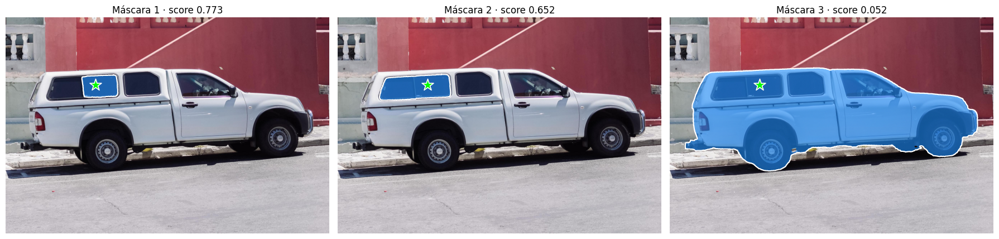

In [ ]:
image = IMG["truck"]
predictor.set_image(image)                         # calcula el embedding de la imagen UNA vez

pts = np.array([[500, 375]]); lab = np.array([1])
masks, scores, logits = predictor.predict(point_coords=pts,
                                          point_labels=lab, multimask_output=True)
order = np.argsort(scores)[::-1]; masks, scores, logits = masks[order], scores[order], logits[order]
print("masks:", masks.shape, "| scores:", scores.round(3))
panel(image, masks, scores, pts, lab)

## 3. Varios puntos: positivos (+) y negativos (−)

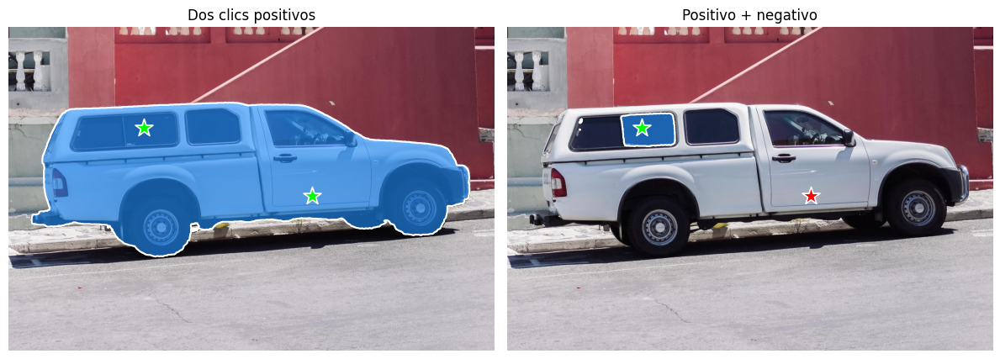

In [ ]:
pts = np.array([[500, 375], [1125, 625]]); lab = np.array([1, 1])
m1, s1, l1 = predictor.predict(point_coords=pts,
                               point_labels=lab, multimask_output=False)
pts2 = np.array([[500, 375], [1125, 625]]); lab2 = np.array([1, 0])
m2, s2, l2 = predictor.predict(point_coords=pts2,
                               point_labels=lab2, multimask_output=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, m, p, l, t in zip(ax, [m1, m2], [pts, pts2], [lab, lab2], ["Dos clics positivos",
                                                                  "Positivo + negativo"]):
    a.imshow(image); show_mask(m[0], a); show_points(p, l, a); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Prompt con caja

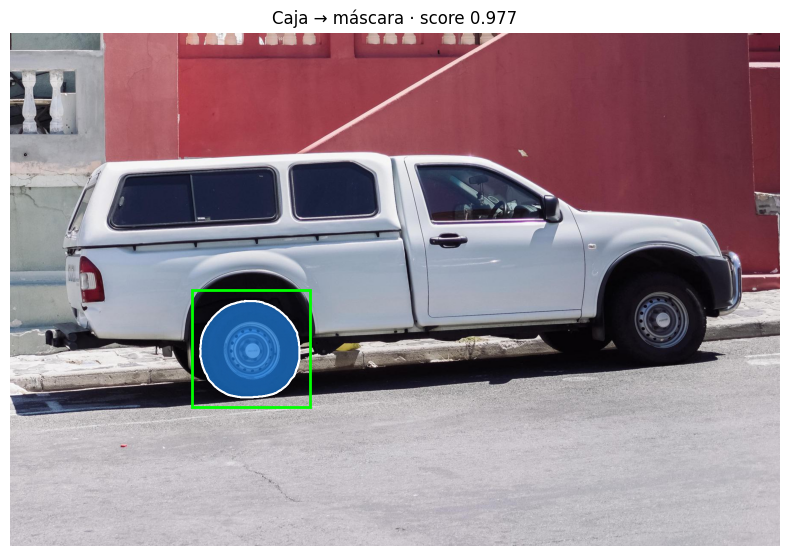

In [ ]:
box = np.array([425, 600, 700, 875])
m, s, _ = predictor.predict(point_coords=None,
                            point_labels=None, box=box[None, :],
                            multimask_output=False)
panel(image, m, s, box=box, titles=[f"Caja → máscara · score {s[0]:.3f}"], size=8)

## 5. Refinamiento iterativo con `mask_input` (logits de la pasada anterior)

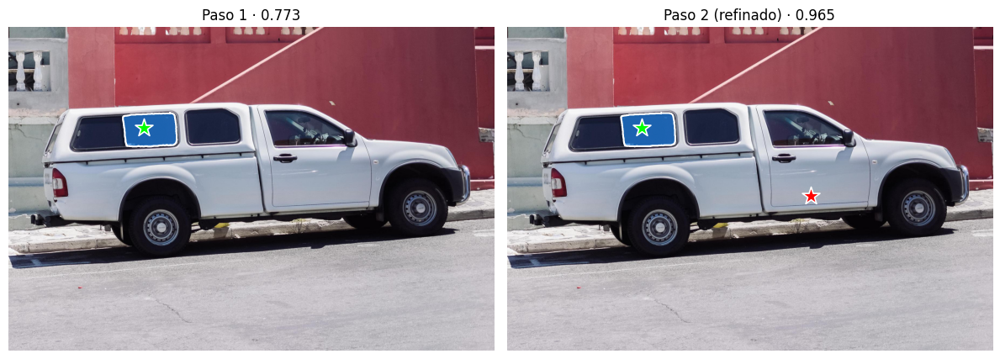

In [ ]:
# 1) primera pasada con un clic
pts = np.array([[500, 375]]); lab = np.array([1])
masks, scores, logits = predictor.predict(point_coords=pts, point_labels=lab, multimask_output=True)
best = int(np.argmax(scores)); mask_input = logits[best][None, :, :]

# 2) segunda pasada: añadimos un clic y reutilizamos la máscara anterior como contexto
pts2 = np.array([[500, 375], [1125, 625]]); lab2 = np.array([1, 0])
refined, rs, _ = predictor.predict(point_coords=pts2, point_labels=lab2, mask_input=mask_input, multimask_output=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(image); show_mask(masks[best], ax[0]); show_points(pts, lab, ax[0]); ax[0].set_title(f"Paso 1 · {scores[best]:.3f}")
ax[1].imshow(image); show_mask(refined[0], ax[1]); show_points(pts2, lab2, ax[1]); ax[1].set_title(f"Paso 2 (refinado) · {rs[0]:.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Recorte (cutout) con el resultado

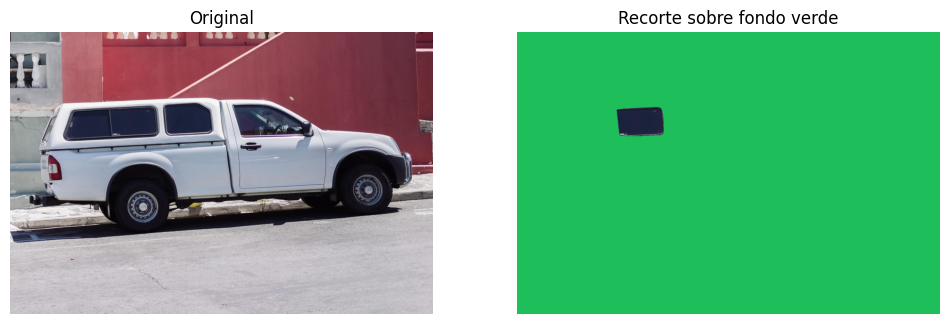

In [ ]:
mask = refined[0].astype(bool)
rgba = np.dstack([image, (mask * 255).astype(np.uint8)])
Image.fromarray(rgba).save("cutout.png")
bg = np.full_like(image, (30, 190, 90)); comp = np.where(mask[..., None], image, bg)
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ax[0].imshow(image); ax[1].imshow(comp)
ax[0].set_title("Original"); ax[1].set_title("Recorte sobre fondo verde"); [a.axis("off") for a in ax]; plt.show()

## 6. Generación automática de máscaras (sin prompts)

55 máscaras en 8.3s


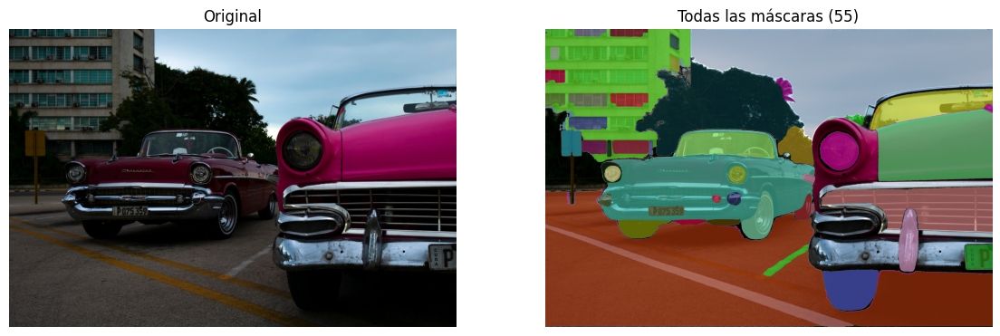

,area,bbox,predicted_iou,stability_score
0,916005,"[0.0, 354.0, 2249.0, 1145.0]",0.988,0.969
1,908962,"[0.0, 814.0, 2249.0, 681.0]",0.996,0.976
2,465391,"[74.0, 0.0, 2175.0, 858.0]",0.992,0.989
3,465226,"[74.0, 0.0, 2175.0, 550.0]",0.992,0.989
4,464584,"[734.0, 0.0, 1515.0, 550.0]",0.996,0.988
5,419053,"[265.0, 504.0, 1089.0, 553.0]",0.977,0.959


In [ ]:
image = IMG["cars"]
gen = SAM2AutomaticMaskGenerator(sam2)             # puntos en cuadrícula 32x32 por defecto
t = time.time(); auto = gen.generate(image); sync(); print(f"{len(auto)} máscaras en {time.time()-t:.1f}s")

def show_anns(anns, ax):
    ax.set_autoscale_on(False)
    layer = np.ones((*anns[0]["segmentation"].shape, 4)); layer[..., 3] = 0
    for a in sorted(anns, key=lambda x: x["area"], reverse=True):
        layer[a["segmentation"]] = np.concatenate([np.random.random(3), [0.6]])
    ax.imshow(layer)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(image); ax[1].imshow(image); show_anns(auto, ax[1])
ax[0].set_title("Original"); ax[1].set_title(f"Todas las máscaras ({len(auto)})"); [a.axis("off") for a in ax]; plt.show()
pd.DataFrame([{k: (round(float(v), 3) if k in ("predicted_iou", "stability_score") else v) for k, v in a.items() if k in ("area", "bbox", "predicted_iou", "stability_score")}
              for a in sorted(auto, key=lambda x: -x["area"])[:6]])

### Ajustar parámetros: densidad de puntos y umbrales

,points_per_side,pred_iou_thresh,stability_thresh,máscaras,segundos
0,16,0.88,0.95,32,2.7
1,32,0.80,0.92,80,8.7
2,64,0.80,0.92,150,32.1


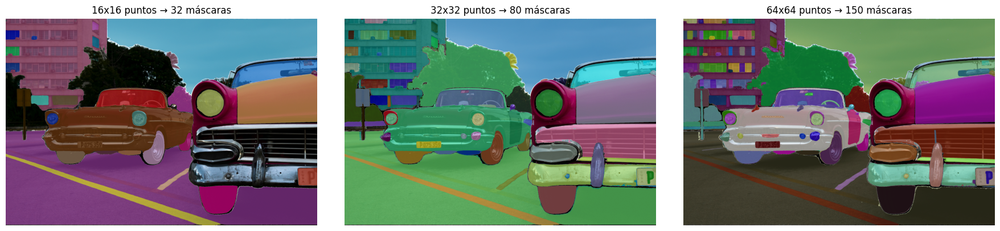

In [ ]:
rows, outs, tit = [], [], []
for pps, iou, stab in [(16, 0.88, 0.95), (32, 0.80, 0.92), (64, 0.80, 0.92)]:
    g = SAM2AutomaticMaskGenerator(sam2, points_per_side=pps, pred_iou_thresh=iou, stability_score_thresh=stab)
    t = time.time(); r = g.generate(image); sync(); dt = time.time() - t
    rows.append([pps, iou, stab, len(r), round(dt, 1)]); outs.append(r); tit.append(f"{pps}x{pps} puntos → {len(r)} máscaras")
display(pd.DataFrame(rows, columns=["points_per_side", "pred_iou_thresh", "stability_thresh", "máscaras", "segundos"]))
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, r, t in zip(ax, outs, tit): a.imshow(image); show_anns(r, a); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## 7. Varias cajas a la vez (usando las cajas del generador automático)

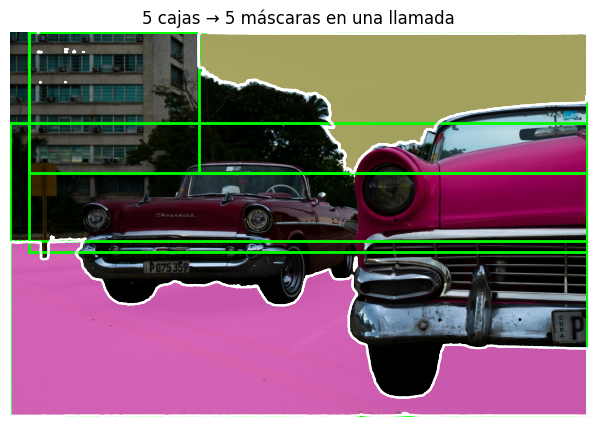

In [ ]:
predictor.set_image(image)
top = sorted(auto, key=lambda x: -x["area"])[:5]
boxes = np.array([[b[0], b[1], b[0]+b[2], b[1]+b[3]] for b in (a["bbox"] for a in top)], dtype=np.float32)
ms, sc, _ = predictor.predict(point_coords=None, point_labels=None, box=boxes, multimask_output=False)
ms = ms.reshape(-1, *image.shape[:2])
plt.figure(figsize=(8, 5)); plt.imshow(image)
for m, b in zip(ms, boxes): show_mask(m, plt.gca(), color=np.concatenate([np.random.random(3), [0.6]])); show_box(b, plt.gca())
plt.title(f"{len(boxes)} cajas → {len(boxes)} máscaras en una llamada"); plt.axis("off"); plt.show()

## 8. Video: preparar los fotogramas

200 fotogramas en notebooks/videos/bedroom


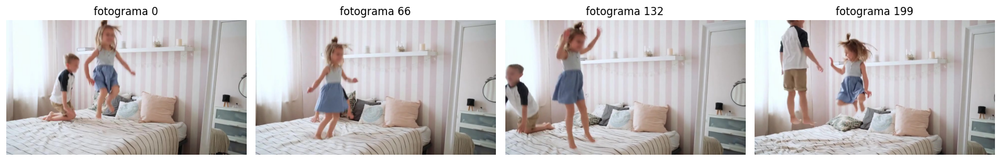

In [ ]:
USE_MY_VIDEO = False      # ← True para subir tu propio video (se extraen ~6 s a 480p)
if USE_MY_VIDEO:
    from google.colab import files
    up = files.upload(); src = list(up.keys())[0]
    !rm -rf my_frames && mkdir -p my_frames
    !ffmpeg -y -loglevel error -i {src} -t 6 -vf "scale=-2:480,fps=15" -q:v 2 -start_number 0 my_frames/%05d.jpg
    video_dir = "my_frames"
else:
    video_dir = "notebooks/videos/bedroom"
frame_names = sorted([p for p in os.listdir(video_dir) if p.lower().endswith((".jpg", ".jpeg"))], key=lambda p: int(os.path.splitext(p)[0]))
print(len(frame_names), "fotogramas en", video_dir)
frames = [np.array(Image.open(os.path.join(video_dir, n)).convert("RGB")) for n in frame_names]
idx = np.linspace(0, len(frames)-1, 4).astype(int)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, i in zip(ax, idx): a.imshow(frames[i]); a.set_title(f"fotograma {i}"); a.axis("off")
plt.tight_layout(); plt.show()

## 9. Prompt en el primer fotograma y propagación (`propagate_in_video`)

frame loading (JPEG): 100%|██████████| 200/200 [00:07<00:00, 25.72it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7813da97305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7813da9076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7813da96f6a2 in

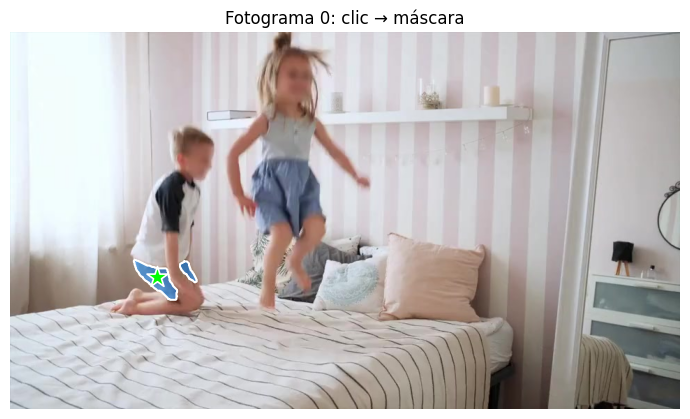

In [ ]:
# Desactivamos el postprocesamiento problemático (fill_holes) al construir el predictor de video
vp = build_sam2_video_predictor(CFG, CKPT, device=device)
# Forzamos a no rellenar huecos en máscaras si da problemas con CUDA/Pytorch en este entorno
vp.fill_holes_in_video_scores = False

state = vp.init_state(video_path=video_dir)
vp.reset_state(state)

def interior_point(mask):
    # punto más "interior" de la máscara (máximo de la transformada de distancia)
    d = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, 5); y, x = np.unravel_index(d.argmax(), d.shape)
    return np.array([[x, y]], dtype=np.float32)

# Clic inicial: en el video de ejemplo, un punto sobre el niño; en tu video, el objeto más grande del fotograma 0
if not USE_MY_VIDEO:
    click1 = np.array([[210, 350]], dtype=np.float32)
else:
    g0 = SAM2AutomaticMaskGenerator(sam2).generate(frames[0]); H, W = frames[0].shape[:2]
    cand = [a for a in sorted(g0, key=lambda x: -x["area"]) if a["area" ] < 0.4*H*W]
    click1 = interior_point(cand[0]["segmentation"])

_, obj_ids, mask_logits = vp.add_new_points_or_box(inference_state=state, frame_idx=0, obj_id=1,
                                                   points=click1, labels=np.array([1], np.int32))
m0 = (mask_logits[0] > 0).cpu().numpy()
panel(frames[0], [m0], points=click1, labels=np.array([1]), titles=["Fotograma 0: clic → máscara"], size=7)

propagate in video:   0%|          | 0/200 [00:00<?, ?it/s]/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7813da97305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7813da9076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7813da96f6a2 in /usr/local/l

200 fotogramas en 244.8s (0.8 fps)


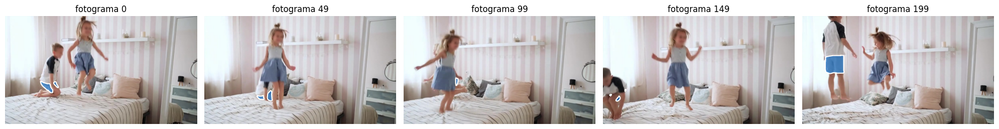

In [ ]:
def propagate(**kw):
    seg = {}
    for f, ids, logits in vp.propagate_in_video(state, **kw):
        seg[f] = {int(o): (logits[i] > 0).cpu().numpy() for i, o in enumerate(ids)}
    return seg

t = time.time(); video_segments = propagate(); sync()
print(f"{len(video_segments)} fotogramas en {time.time()-t:.1f}s ({len(video_segments)/(time.time()-t):.1f} fps)")
show_idx = np.linspace(0, len(frames)-1, 5).astype(int)
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, i in zip(ax, show_idx):
    a.imshow(frames[i]); [show_mask(m, a) for m in video_segments[i].values()]; a.set_title(f"fotograma {i}"); a.axis("off")
plt.tight_layout(); plt.show()

## 10. Varios objetos a la vez (cada uno con su `obj_id`)

/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7813da97305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7813da9076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7813da96f6a2 in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #3: 

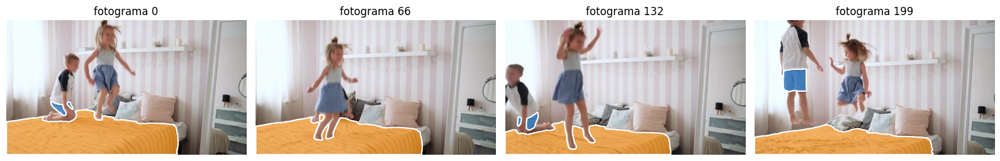

In [ ]:
# Segundo objeto: la máscara automática más grande del fotograma 0 que no se solape con el objeto 1
g0 = SAM2AutomaticMaskGenerator(sam2).generate(frames[0]); H, W = frames[0].shape[:2]
cands = [a for a in sorted(g0, key=lambda x: -x["area"])
         if a["area"] < 0.4*H*W and (a["segmentation"] & m0.reshape(H, W)).sum() < 0.05*a["area"]]
click2 = interior_point(cands[0]["segmentation"])
vp.add_new_points_or_box(inference_state=state, frame_idx=0, obj_id=2, points=click2, labels=np.array([1], np.int32))

video_segments = propagate()
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
cols = {1: np.array([30/255, 144/255, 255/255, .6]), 2: np.array([255/255, 140/255, 0, .6])}
for a, i in zip(ax, np.linspace(0, len(frames)-1, 4).astype(int)):
    a.imshow(frames[i]); [show_mask(m, a, cols.get(o)) for o, m in video_segments[i].items()]; a.set_title(f"fotograma {i}"); a.axis("off")
plt.tight_layout(); plt.show()

## 11. Corregir en un fotograma intermedio y volver a propagar

propagate in video: 100%|██████████| 200/200 [04:58<00:00,  1.49s/it]


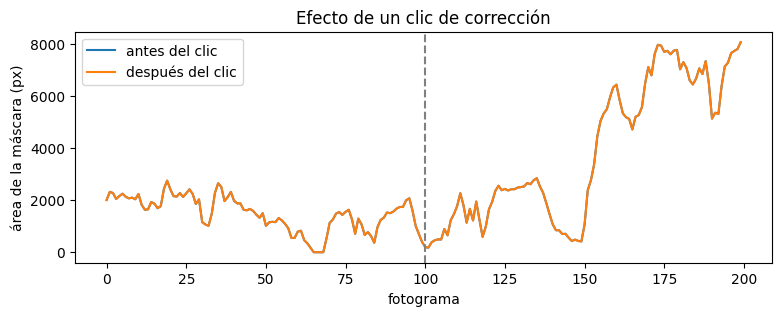

In [ ]:
mid = len(frames) // 2
before = {f: int(s[1].sum()) for f, s in video_segments.items()}
click_mid = interior_point(video_segments[mid][1].reshape(H, W))
vp.add_new_points_or_box(inference_state=state, frame_idx=mid, obj_id=1, points=click_mid, labels=np.array([1], np.int32))
video_segments = propagate()
after = {f: int(s[1].sum()) for f, s in video_segments.items()}

plt.figure(figsize=(9, 3)); plt.plot(list(before.keys()), list(before.values()), label="antes del clic")
plt.plot(list(after.keys()), list(after.values()), label="después del clic"); plt.axvline(mid, ls="--", c="gray")
plt.xlabel("fotograma"); plt.ylabel("área de la máscara (px)"); plt.legend(); plt.title("Efecto de un clic de corrección"); plt.show()

### Propagar hacia atrás (`reverse=True`)

propagate in video: 100%|██████████| 101/101 [02:32<00:00,  1.51s/it]


Fotogramas hacia atrás desde 100 : 101


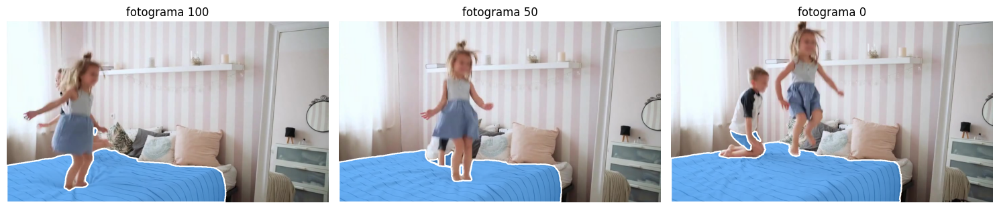

In [ ]:
rev = propagate(start_frame_idx=mid, reverse=True)
print("Fotogramas hacia atrás desde", mid, ":", len(rev))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, i in zip(ax, [mid, mid//2, 0]):
    a.imshow(frames[i]); [show_mask(m, a) for m in rev[i].values()]; a.set_title(f"fotograma {i}"); a.axis("off")
plt.tight_layout(); plt.show()

## 12. Video final con las máscaras superpuestas

In [ ]:
from IPython.display import HTML
from base64 import b64encode
video_segments = propagate()
palette = {1: (255, 144, 30), 2: (0, 140, 255), 3: (60, 200, 60)}      # BGR
Hh, Ww = frames[0].shape[:2]; scale = 640 / Ww; size = (640, int(Hh * scale))
vw = cv2.VideoWriter("sam2_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 15, size)
for i, fr in enumerate(frames):
    out = cv2.cvtColor(fr, cv2.COLOR_RGB2BGR).copy()
    for o, m in video_segments.get(i, {}).items():
        m = m.reshape(Hh, Ww).astype(np.uint8); col = np.zeros_like(out); col[:] = palette.get(o, (0, 255, 255))
        out = np.where(m[..., None] > 0, (0.45*out + 0.55*col).astype(np.uint8), out)
        cv2.drawContours(out, cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0], -1, (255, 255, 255), 2)
    vw.write(cv2.resize(out, size))
vw.release()
!ffmpeg -y -loglevel error -i sam2_raw.mp4 -vcodec libx264 sam2_video.mp4
data = b64encode(open("sam2_video.mp4", "rb").read()).decode()
HTML(f'<video width=560 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

propagate in video: 100%|██████████| 200/200 [04:56<00:00,  1.48s/it]


## 13. Tamaños de modelo: Tiny vs Large

,modelo,parámetros (M),codificar imagen (ms),predecir máscara (ms),score
0,tiny,39.0,245,17.9,0.934
1,large,224.4,953,13.3,0.773


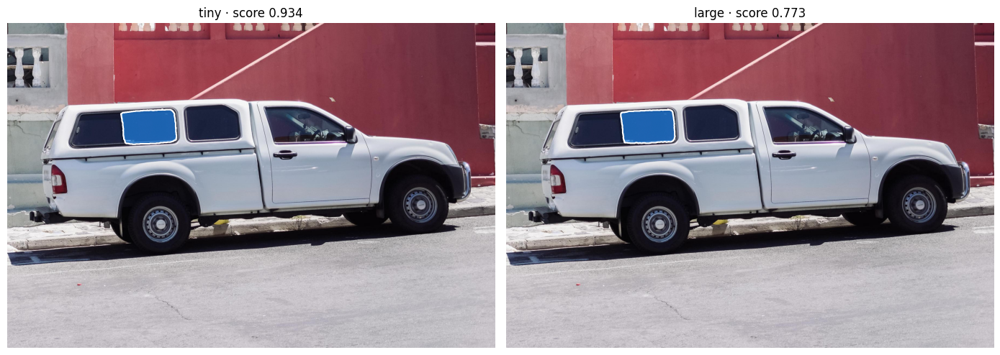

In [ ]:
rows, outs, tit = [], [], []
image = IMG["truck"]; pts = np.array([[500, 375]]); lab = np.array([1])
for name in ["tiny", "large"]:
    ck, cf = MODELS[name]; m_ = build_sam2(cf, ck, device=device); p_ = SAM2ImagePredictor(m_)
    p_.set_image(image); p_.predict(point_coords=pts, point_labels=lab, multimask_output=False)            # calentamiento
    sync(); t = time.time(); p_.set_image(image); sync(); t_enc = time.time() - t
    t = time.time(); mk, sc, _ = p_.predict(point_coords=pts, point_labels=lab, multimask_output=False); sync(); t_dec = time.time() - t
    rows.append([name, round(sum(p.numel() for p in m_.parameters())/1e6, 1), round(t_enc*1000), round(t_dec*1000, 1), round(float(sc[0]), 3)])
    outs.append(mk[0]); tit.append(f"{name} · score {sc[0]:.3f}")
display(pd.DataFrame(rows, columns=["modelo", "parámetros (M)", "codificar imagen (ms)", "predecir máscara (ms)", "score"]))
panel(image, outs, titles=tit, size=7)

## ✅ Resumen
| Pieza | Para qué sirve |
|---|---|
| `SAM2ImagePredictor.set_image / predict` | Segmentar con puntos, cajas o máscaras |
| `multimask_output`, `mask_input` | Candidatas y refinamiento iterativo |
| `SAM2AutomaticMaskGenerator` | Segmentar todo sin prompts |
| `build_sam2_video_predictor` | Segmentación en video |
| `add_new_points_or_box` | Prompt en cualquier fotograma, por `obj_id` |
| `propagate_in_video` | Propagar y rastrear (adelante y atrás) |
| Tiny / Small / Base+ / Large | Velocidad vs calidad |